# Campaign worksheet inspection and consolidation

Inspect all campaign worksheets, verify their schemas, then combine them into one analytical table with campaign type and source-sheet traceability.

Geographic hierarchy: **Continent → Country → City**. Campaign latitude and longitude remain at record level.

In [1]:
from pathlib import Path
import pandas as pd

workbook_path = Path("office_files.xlsx")
sheets = pd.read_excel(workbook_path, sheet_name=None)

print(f"Worksheets found: {len(sheets)}")
for sheet_name, frame in sheets.items():
    print(f"\nWorksheet: {sheet_name}")
    print(f"Shape: {frame.shape}")
    print(f"Fields ({len(frame.columns)}): {frame.columns.tolist()}")
    display(frame.head(3))

Worksheets found: 3

Worksheet: National Campaigns
Shape: (50, 10)
Fields (10): ['Campaign_ID', 'Organization', 'Country', 'City', 'Latitude', 'Longitude', 'Start_Date', 'End_Date', 'Focus_Area', 'Intensity_Score']


,Campaign_ID,Organization,Country,City,Latitude,Longitude,Start_Date,End_Date,Focus_Area,Intensity_Score
0,NAT-001,Transparency Alliance,Mexico,Mexico City,18.9770,-98.2823,2024-06-01,2025-07-05,Political Finance,8
1,NAT-002,Transparency Alliance,Kenya,Nairobi,-1.1075,37.8271,2022-06-09,2023-11-23,Bribery Enforcement,6
2,NAT-003,Ethics Forward,Kenya,Nairobi,-2.3322,35.5107,2022-04-01,2023-05-22,Political Finance,2



Worksheet: Regional Initiatives
Shape: (50, 10)
Fields (10): ['Campaign_ID', 'Organization', 'Country', 'City', 'Latitude', 'Longitude', 'Start_Date', 'End_Date', 'Focus_Area', 'Intensity_Score']


,Campaign_ID,Organization,Country,City,Latitude,Longitude,Start_Date,End_Date,Focus_Area,Intensity_Score
0,REG-001,Ethics Forward,Indonesia,Jakarta,-5.3154,108.3223,2024-04-08,2024-12-06,Judicial Integrity,5
1,REG-002,Ethics Forward,India,New Delhi,30.0018,78.5589,2022-05-11,2023-06-15,Bribery Enforcement,1
2,REG-003,Accountability Network,Germany,Berlin,52.2902,12.3050,2022-10-13,2023-10-14,Bribery Enforcement,1



Worksheet: NGO Programs
Shape: (50, 10)
Fields (10): ['Campaign_ID', 'Organization', 'Country', 'City', 'Latitude', 'Longitude', 'Start_Date', 'End_Date', 'Focus_Area', 'Intensity_Score']


,Campaign_ID,Organization,Country,City,Latitude,Longitude,Start_Date,End_Date,Focus_Area,Intensity_Score
0,NGO-001,Transparency Alliance,Germany,Berlin,53.1977,14.5231,2024-01-23,2025-09-04,Corporate Compliance,8
1,NGO-002,Accountability Network,Mexico,Mexico City,20.3209,-99.4107,2022-07-25,2022-11-16,Judicial Integrity,2
2,NGO-003,Ethics Forward,Kenya,Nairobi,-1.9836,37.3007,2024-06-16,2025-08-09,Bribery Enforcement,3


## Build the analytical table

Validate the worksheet count and identical 10-field schema, append the source worksheet as both `campaign_type` and `source_sheet`, retain `Campaign_ID`, and export the combined rows to a separate workbook.

In [2]:
assert len(sheets) == 3, f"Expected 3 worksheets, found {len(sheets)}"

source_sheet_names = list(sheets)
original_columns = list(next(iter(sheets.values())).columns)
assert len(original_columns) == 10, f"Expected 10 fields, found {len(original_columns)}"

for sheet_name, frame in sheets.items():
    assert list(frame.columns) == original_columns, (
        f"Worksheet {sheet_name!r} does not match the first worksheet's 10-field schema"
    )

country_to_continent = {
    'Brazil': 'South America',
    'Germany': 'Europe',
    'India': 'Asia',
    'Indonesia': 'Asia',
    'Kenya': 'Africa',
    'Mexico': 'North America',
    'Nigeria': 'Africa',
    'Philippines': 'Asia',
    'South Africa': 'Africa',
    'United States': 'North America',
}

campaign_frames = []
for sheet_name, frame in sheets.items():
    campaign = frame.copy()
    campaign.insert(2, 'Continent', campaign['Country'].map(country_to_continent))
    assert campaign['Continent'].notna().all(), f"Unmapped countries in {sheet_name!r}"
    campaign["campaign_type"] = sheet_name
    campaign["source_sheet"] = sheet_name
    campaign_frames.append(campaign)

analytical_table = pd.concat(campaign_frames, ignore_index=True)
expected_rows = sum(len(frame) for frame in sheets.values())
assert len(analytical_table) == expected_rows
assert analytical_table["Campaign_ID"].tolist() == [
    campaign_id for frame in sheets.values() for campaign_id in frame["Campaign_ID"].tolist()
]
assert analytical_table["campaign_type"].equals(analytical_table["source_sheet"])
assert analytical_table['Continent'].notna().all()
assert set(analytical_table['Continent']) == set(country_to_continent.values())

output_path = workbook_path.with_name("campaigns_analytical_table.xlsx")
analytical_table.to_excel(output_path, index=False, sheet_name="Campaigns")
exported_table = pd.read_excel(output_path)
assert exported_table.shape == analytical_table.shape
assert list(exported_table.columns) == list(analytical_table.columns)
assert exported_table["Campaign_ID"].tolist() == analytical_table["Campaign_ID"].tolist()
assert exported_table['Continent'].equals(analytical_table['Continent'])
assert exported_table["campaign_type"].equals(exported_table["source_sheet"])

print(f"Verified worksheets: {source_sheet_names}")
print(f"Shared original fields ({len(original_columns)}): {original_columns}")
print(f"Combined rows: {len(analytical_table)}")
print("Geographic hierarchy: Continent -> Country -> City")
print("Export read-back validation passed.")
print(f"Output: {output_path}")
display(analytical_table.head())
display(analytical_table.groupby(["campaign_type", "source_sheet"], sort=False).size().rename("row_count"))

Verified worksheets: ['National Campaigns', 'Regional Initiatives', 'NGO Programs']
Shared original fields (10): ['Campaign_ID', 'Organization', 'Country', 'City', 'Latitude', 'Longitude', 'Start_Date', 'End_Date', 'Focus_Area', 'Intensity_Score']
Combined rows: 150
Geographic hierarchy: Continent -> Country -> City
Export read-back validation passed.
Output: campaigns_analytical_table.xlsx


,Campaign_ID,Organization,Continent,Country,City,Latitude,Longitude,Start_Date,End_Date,Focus_Area,Intensity_Score,campaign_type,source_sheet
0,NAT-001,Transparency Alliance,North America,Mexico,Mexico City,18.9770,-98.2823,2024-06-01,2025-07-05,Political Finance,8,National Campaigns,National Campaigns
1,NAT-002,Transparency Alliance,Africa,Kenya,Nairobi,-1.1075,37.8271,2022-06-09,2023-11-23,Bribery Enforcement,6,National Campaigns,National Campaigns
2,NAT-003,Ethics Forward,Africa,Kenya,Nairobi,-2.3322,35.5107,2022-04-01,2023-05-22,Political Finance,2,National Campaigns,National Campaigns
3,NAT-004,Global Integrity Group,North America,Mexico,Mexico City,20.7216,-98.2755,2023-10-27,2025-01-08,Public Procurement,3,National Campaigns,National Campaigns
4,NAT-005,Global Integrity Group,South America,Brazil,Brasilia,-16.0788,-48.7132,2023-07-17,2024-10-20,Political Finance,4,National Campaigns,National Campaigns


campaign_type         source_sheet        
National Campaigns    National Campaigns      50
Regional Initiatives  Regional Initiatives    50
NGO Programs          NGO Programs            50
Name: row_count, dtype: int64

## Data-quality assessment

Check record and ID counts, missing values, date parseability and ordering, score ranges, coordinate bounds, naming consistency, and duplicate campaign records across source worksheets.

In [3]:
quality_df = pd.read_excel(output_path, sheet_name="Campaigns")
print(f"Total records: {len(quality_df)}")
print(f"Distinct campaign IDs: {quality_df['Campaign_ID'].nunique(dropna=True)}")
duplicate_id_rows = quality_df[quality_df['Campaign_ID'].duplicated(keep=False)].sort_values('Campaign_ID')
print(f"Rows with repeated Campaign_ID: {len(duplicate_id_rows)}")
cross_sheet_ids = quality_df.groupby('Campaign_ID')['source_sheet'].nunique()
cross_sheet_ids = cross_sheet_ids[cross_sheet_ids > 1].index
print(f"Campaign_IDs appearing in multiple worksheets: {len(cross_sheet_ids)}")
if len(cross_sheet_ids):
    display(quality_df[quality_df['Campaign_ID'].isin(cross_sheet_ids)].sort_values('Campaign_ID'))

missing_counts = quality_df.isna().sum()
print("Missing values by field:")
display(missing_counts.rename('missing_count').to_frame())

for date_column in ['Start_Date', 'End_Date']:
    parsed_dates = pd.to_datetime(quality_df[date_column], errors='coerce')
    invalid_dates = quality_df[date_column].notna() & parsed_dates.isna()
    print(f"{date_column}: dtype={quality_df[date_column].dtype}, invalid nonmissing values={invalid_dates.sum()}")
    if invalid_dates.any():
        display(quality_df.loc[invalid_dates, ['Campaign_ID', 'source_sheet', date_column]])
    else:
        quality_df[date_column] = parsed_dates
date_order_issues = quality_df['End_Date'] < quality_df['Start_Date']
print(f"Rows with End_Date before Start_Date: {date_order_issues.sum()}")

score = pd.to_numeric(quality_df['Intensity_Score'], errors='coerce')
print(f"Intensity_Score min/max: {score.min()} / {score.max()}; observed values: {sorted(score.dropna().unique().tolist())}")
print(f"Intensity_Score missing/non-numeric: {score.isna().sum()}")
print(f"Intensity_Score outside assumed 1-10 scale: {((score < 1) | (score > 10)).sum()}")

latitude = pd.to_numeric(quality_df['Latitude'], errors='coerce')
longitude = pd.to_numeric(quality_df['Longitude'], errors='coerce')
invalid_coordinates = latitude.isna() | longitude.isna() | ~latitude.between(-90, 90) | ~longitude.between(-180, 180)
print(f"Impossible/missing coordinate pairs by global bounds: {invalid_coordinates.sum()}")
if invalid_coordinates.any():
    display(quality_df.loc[invalid_coordinates, ['Campaign_ID', 'Country', 'City', 'Latitude', 'Longitude']])
city_groups = quality_df.groupby(['Country', 'City'], dropna=False).agg(
    records=('Campaign_ID', 'size'),
    latitude_min=('Latitude', 'min'),
    latitude_max=('Latitude', 'max'),
    longitude_min=('Longitude', 'min'),
    longitude_max=('Longitude', 'max'),
).reset_index()
print(f"Unique country/city combinations: {len(city_groups)}")
print("Repeated city groups with their observed coordinate ranges:")
display(city_groups[city_groups['records'] > 1].sort_values(['Country', 'City']))

for text_column in ['Organization', 'Country', 'City', 'Focus_Area']:
    raw = quality_df[text_column].astype('string')
    trimmed = raw.str.strip()
    normalized = trimmed.str.casefold()
    variants = pd.DataFrame({'raw': raw, 'normalized': normalized}).dropna().groupby('normalized')['raw'].agg(lambda values: sorted(set(values)))
    variants = variants[variants.map(len) > 1]
    print(f"{text_column}: unique raw values={raw.nunique(dropna=True)}, blank/whitespace-only={(trimmed == '').sum()}, case/space variants={len(variants)}")
    if len(variants):
        display(variants.rename('variants').to_frame())

duplicate_key = ['Organization', 'Country', 'City', 'Start_Date', 'End_Date', 'Focus_Area']
duplicate_mask = quality_df.duplicated(duplicate_key, keep=False)
candidate_duplicates = quality_df.loc[duplicate_mask].sort_values(duplicate_key + ['source_sheet'])
cross_sheet_duplicate_mask = candidate_duplicates.groupby(duplicate_key, dropna=False)['source_sheet'].transform('nunique') > 1 if len(candidate_duplicates) else pd.Series(dtype=bool)
cross_sheet_duplicates = candidate_duplicates.loc[cross_sheet_duplicate_mask] if len(candidate_duplicates) else candidate_duplicates
print(f"Cross-worksheet duplicate campaign candidates (same organization, country, city, dates, focus): {len(cross_sheet_duplicates)} rows")
if len(cross_sheet_duplicates):
    display(cross_sheet_duplicates[duplicate_key + ['Campaign_ID', 'source_sheet', 'Latitude', 'Longitude', 'Intensity_Score']])

Total records: 150
Distinct campaign IDs: 150
Rows with repeated Campaign_ID: 0
Campaign_IDs appearing in multiple worksheets: 0
Missing values by field:


,missing_count
Campaign_ID,0
Organization,0
Continent,0
Country,0
City,0
Latitude,0
Longitude,0
Start_Date,0
End_Date,0
Focus_Area,0


Start_Date: dtype=object, invalid nonmissing values=0
End_Date: dtype=object, invalid nonmissing values=0
Rows with End_Date before Start_Date: 0
Intensity_Score min/max: 1 / 10; observed values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Intensity_Score missing/non-numeric: 0
Intensity_Score outside assumed 1-10 scale: 0
Impossible/missing coordinate pairs by global bounds: 0
Unique country/city combinations: 10
Repeated city groups with their observed coordinate ranges:


,Country,City,records,latitude_min,latitude_max,longitude_min,longitude_max
0,Brazil,Brasilia,17,-16.9741,-14.6712,-49.3413,-46.4424
1,Germany,Berlin,17,51.3651,53.5385,12.2012,14.6780
2,India,New Delhi,13,27.5218,30.0018,76.4117,78.5589
3,Indonesia,Jakarta,17,-7.1393,-4.9545,105.3785,108.3223
4,Kenya,Nairobi,13,-2.7600,0.0407,35.5107,37.8271
5,Mexico,Mexico City,11,17.9670,20.7216,-100.1203,-97.6541
6,Nigeria,Abuja,16,7.7128,10.4873,6.0196,8.7120
7,Philippines,Manila,17,13.1014,16.0463,119.5362,121.8131
8,South Africa,Pretoria,17,-27.0602,-24.2827,26.7296,29.4175
9,United States,Washington DC,12,37.5383,40.3422,-78.4511,-75.7940


Organization: unique raw values=5, blank/whitespace-only=0, case/space variants=0
Country: unique raw values=10, blank/whitespace-only=0, case/space variants=0
City: unique raw values=10, blank/whitespace-only=0, case/space variants=0
Focus_Area: unique raw values=5, blank/whitespace-only=0, case/space variants=0
Cross-worksheet duplicate campaign candidates (same organization, country, city, dates, focus): 0 rows


## Standardize fields and flag city-coordinate outliers

Normalize whitespace without changing proper-name capitalization, convert dates to pandas datetimes, and flag coordinates more than 50 km from the named city's approximate center. This distance test is a review heuristic, not an administrative-boundary determination.

In [4]:
import numpy as np

clean_df = quality_df.copy()
name_columns = ['Organization', 'Country', 'City', 'Focus_Area']
name_change_counts = {}
for column in name_columns:
    original = clean_df[column].astype('string')
    standardized = original.str.strip().str.replace(r'\s+', ' ', regex=True)
    name_change_counts[column] = int((original != standardized).fillna(False).sum())
    clean_df[column] = standardized

date_parse_errors = 0
for column in ['Start_Date', 'End_Date']:
    parsed = pd.to_datetime(clean_df[column], errors='coerce')
    invalid = clean_df[column].notna() & parsed.isna()
    date_parse_errors += int(invalid.sum())
    clean_df[column] = parsed
date_order_invalid = clean_df['End_Date'] < clean_df['Start_Date']

clean_df['Intensity_Score'] = pd.to_numeric(clean_df['Intensity_Score'], errors='coerce')
score_valid = clean_df['Intensity_Score'].between(1, 10)
clean_df['coordinate_bounds_valid'] = (
    pd.to_numeric(clean_df['Latitude'], errors='coerce').between(-90, 90)
    & pd.to_numeric(clean_df['Longitude'], errors='coerce').between(-180, 180)
)

city_centers = {
    ('Brazil', 'Brasilia'): (-15.7939, -47.8828),
    ('Germany', 'Berlin'): (52.5200, 13.4050),
    ('India', 'New Delhi'): (28.6139, 77.2090),
    ('Indonesia', 'Jakarta'): (-6.2088, 106.8456),
    ('Kenya', 'Nairobi'): (-1.2864, 36.8172),
    ('Mexico', 'Mexico City'): (19.4326, -99.1332),
    ('Nigeria', 'Abuja'): (9.0765, 7.3986),
    ('Philippines', 'Manila'): (14.5995, 120.9842),
    ('South Africa', 'Pretoria'): (-25.7479, 28.2293),
    ('United States', 'Washington DC'): (38.9072, -77.0369),
}
city_keys = list(zip(clean_df['Country'], clean_df['City']))
unknown_city_keys = sorted(set(city_keys) - set(city_centers))
assert not unknown_city_keys, f"No city-center reference for: {unknown_city_keys}"
center_coordinates = np.array([city_centers[key] for key in city_keys], dtype=float)
latitude_radians = np.radians(pd.to_numeric(clean_df['Latitude'], errors='coerce').to_numpy(dtype=float))
longitude_radians = np.radians(pd.to_numeric(clean_df['Longitude'], errors='coerce').to_numpy(dtype=float))
center_latitude_radians = np.radians(center_coordinates[:, 0])
center_longitude_radians = np.radians(center_coordinates[:, 1])
delta_latitude = latitude_radians - center_latitude_radians
delta_longitude = longitude_radians - center_longitude_radians
haversine = np.sin(delta_latitude / 2) ** 2 + np.cos(latitude_radians) * np.cos(center_latitude_radians) * np.sin(delta_longitude / 2) ** 2
clean_df['city_center_distance_km'] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))
clean_df['outside_50km_city_center'] = clean_df['city_center_distance_km'] > 50

duplicate_key = ['Organization', 'Country', 'City', 'Start_Date', 'End_Date', 'Focus_Area']
duplicate_candidates = clean_df[clean_df.duplicated(duplicate_key, keep=False)].copy()
if len(duplicate_candidates):
    cross_sheet_mask = duplicate_candidates.groupby(duplicate_key, dropna=False)['source_sheet'].transform('nunique') > 1
    cross_sheet_duplicates = duplicate_candidates.loc[cross_sheet_mask].copy()
else:
    cross_sheet_duplicates = duplicate_candidates.copy()

quality_summary = pd.DataFrame([
    ('Total records', 'PASS', str(len(clean_df))),
    ('Unique Campaign_ID', 'PASS' if clean_df['Campaign_ID'].nunique(dropna=True) == len(clean_df) else 'FLAG', f"{clean_df['Campaign_ID'].nunique(dropna=True)} distinct of {len(clean_df)} records"),
    ('Geographic mapping', 'PASS' if clean_df['Continent'].notna().all() else 'FLAG', f"{clean_df['Continent'].nunique()} continents and {clean_df[['Country', 'City']].drop_duplicates().shape[0]} country-city combinations"),
    ('Missing values', 'PASS' if int(clean_df.isna().sum().sum()) == 0 else 'FLAG', f"{int(clean_df.isna().sum().sum())} missing cells"),
    ('Date parsing', 'PASS' if date_parse_errors == 0 else 'FLAG', f"{date_parse_errors} nonmissing values failed parsing; exported as Excel dates"),
    ('Date order', 'PASS' if not date_order_invalid.any() else 'FLAG', f"{int(date_order_invalid.sum())} End_Date values precede Start_Date"),
    ('Intensity_Score', 'PASS' if score_valid.all() else 'FLAG', f"{int((~score_valid).sum())} values outside the inferred 1-10 scale"),
    ('Coordinate global bounds', 'PASS' if clean_df['coordinate_bounds_valid'].all() else 'FLAG', f"{int((~clean_df['coordinate_bounds_valid']).sum())} coordinate pairs outside latitude/longitude bounds"),
    ('City-center distance', 'FLAG' if clean_df['outside_50km_city_center'].any() else 'PASS', f"{int(clean_df['outside_50km_city_center'].sum())} records are more than 50 km from approximate city center"),
    ('Name whitespace standardization', 'PASS' if sum(name_change_counts.values()) == 0 else 'STANDARDIZED', f"Changes by field: {name_change_counts}; capitalization preserved"),
    ('Cross-worksheet duplicate candidates', 'FLAG' if len(cross_sheet_duplicates) else 'PASS', f"{len(cross_sheet_duplicates)} rows match the same organization, country, city, dates, and focus across worksheets"),
], columns=['check', 'status', 'details'])

city_reference = pd.DataFrame([
    {'Continent': country_to_continent[country], 'Country': country, 'City': city, 'reference_latitude': coordinates[0], 'reference_longitude': coordinates[1], 'distance_threshold_km': 50}
    for (country, city), coordinates in city_centers.items()
])
geography_dimension = clean_df.groupby(['Continent', 'Country', 'City'], as_index=False).size()
geography_dimension = geography_dimension.rename(columns={'size': 'campaign_count'}).sort_values(['Continent', 'Country', 'City'])
assert geography_dimension['campaign_count'].sum() == len(clean_df)
coordinate_flags = clean_df.loc[clean_df['outside_50km_city_center'], [
    'Campaign_ID', 'Organization', 'Country', 'City', 'Latitude', 'Longitude',
    'city_center_distance_km', 'source_sheet'
]].sort_values(['Country', 'City', 'city_center_distance_km'], ascending=[True, True, False])

quality_output_path = workbook_path.with_name('campaigns_data_quality.xlsx')
with pd.ExcelWriter(quality_output_path, engine='openpyxl', date_format='yyyy-mm-dd', datetime_format='yyyy-mm-dd') as writer:
    clean_df.to_excel(writer, index=False, sheet_name='Campaigns')
    quality_summary.to_excel(writer, index=False, sheet_name='Quality_Summary')
    coordinate_flags.to_excel(writer, index=False, sheet_name='Coordinate_Flags')
    cross_sheet_duplicates.to_excel(writer, index=False, sheet_name='Duplicate_Candidates')
    geography_dimension.to_excel(writer, index=False, sheet_name='Geography')
    city_reference.to_excel(writer, index=False, sheet_name='City_Center_Reference')

exported_quality_df = pd.read_excel(quality_output_path, sheet_name='Campaigns')
assert len(exported_quality_df) == len(clean_df)
assert exported_quality_df['Campaign_ID'].tolist() == clean_df['Campaign_ID'].tolist()
assert exported_quality_df['Continent'].equals(clean_df['Continent'])
assert pd.api.types.is_datetime64_any_dtype(exported_quality_df['Start_Date'])
assert pd.api.types.is_datetime64_any_dtype(exported_quality_df['End_Date'])
assert exported_quality_df['source_sheet'].equals(clean_df['source_sheet'])
exported_geography = pd.read_excel(quality_output_path, sheet_name='Geography')
assert exported_geography['campaign_count'].sum() == len(clean_df)
print('Quality workbook read-back and Excel date validation passed.')
print(quality_summary.to_string(index=False))
print(f"\nCoordinate flags: {len(coordinate_flags)} of {len(clean_df)} records exceed 50 km")
print(f"Standardized text changes: {name_change_counts}")
print(f"Quality workbook: {quality_output_path}")
display(coordinate_flags.head(20))

Quality workbook read-back and Excel date validation passed.
                               check status                                                                                                   details
                       Total records   PASS                                                                                                       150
                  Unique Campaign_ID   PASS                                                                               150 distinct of 150 records
                  Geographic mapping   PASS                                                             5 continents and 10 country-city combinations
                      Missing values   PASS                                                                                           0 missing cells
                        Date parsing   PASS                                               0 nonmissing values failed parsing; exported as Excel dates
                          Date order   

,Campaign_ID,Organization,Country,City,Latitude,Longitude,city_center_distance_km,source_sheet
136,NGO-037,Accountability Network,Brazil,Brasilia,-16.9505,-49.3413,201.868451,NGO Programs
72,REG-023,Transparency Alliance,Brazil,Brasilia,-16.6151,-46.5497,169.114615,Regional Initiatives
60,REG-011,Global Integrity Group,Brazil,Brasilia,-15.9402,-46.4424,154.919028,Regional Initiatives
111,NGO-012,Global Integrity Group,Brazil,Brasilia,-16.7367,-47.0048,140.619378,NGO Programs
43,NAT-044,Accountability Network,Brazil,Brasilia,-16.9741,-47.4095,140.610211,National Campaigns
99,REG-050,Global Integrity Group,Brazil,Brasilia,-14.6712,-48.3128,133.090092,Regional Initiatives
61,REG-012,Transparency Alliance,Brazil,Brasilia,-16.3341,-48.9489,128.782306,Regional Initiatives
38,NAT-039,Transparency Alliance,Brazil,Brasilia,-15.7949,-46.7731,118.734336,National Campaigns
121,NGO-022,Accountability Network,Brazil,Brasilia,-16.0993,-48.8935,113.270201,NGO Programs
20,NAT-021,Transparency Alliance,Brazil,Brasilia,-15.2852,-47.0267,107.754520,National Campaigns


## Overall campaign profile

Summarize campaign timing, intensity, type, geography, focus, and organization coverage. Organizational activity across multiple countries is not treated as proof that an individual campaign is global; campaign IDs are the campaign-level identifiers in this dataset.

In [5]:
total_campaigns = clean_df['Campaign_ID'].nunique()
duration_days = (clean_df['End_Date'] - clean_df['Start_Date']).dt.days
profile_overview = pd.DataFrame([
    ('Campaign records', len(clean_df)),
    ('Unique campaign IDs', total_campaigns),
    ('Campaign types', clean_df['campaign_type'].nunique()),
    ('Organizations', clean_df['Organization'].nunique()),
    ('Continents', clean_df['Continent'].nunique()),
    ('Countries', clean_df['Country'].nunique()),
    ('Cities', clean_df['City'].nunique()),
    ('Focus areas', clean_df['Focus_Area'].nunique()),
    ('Start-date coverage', f"{clean_df['Start_Date'].min():%Y-%m-%d} to {clean_df['Start_Date'].max():%Y-%m-%d}"),
    ('End-date coverage', f"{clean_df['End_Date'].min():%Y-%m-%d} to {clean_df['End_Date'].max():%Y-%m-%d}"),
    ('Mean intensity score', round(clean_df['Intensity_Score'].mean(), 2)),
    ('Median intensity score', round(clean_df['Intensity_Score'].median(), 2)),
    ('Mean campaign duration (days)', round(duration_days.mean(), 1)),
    ('Median campaign duration (days)', round(duration_days.median(), 1)),
    ('Global campaign definition', 'One coordinated campaign with documented activity in at least two countries; current IDs do not link records across countries.'),
], columns=['metric', 'value'])

by_campaign_type = clean_df.groupby('campaign_type').agg(
    campaigns=('Campaign_ID', 'nunique'),
    countries=('Country', 'nunique'),
    mean_intensity=('Intensity_Score', 'mean'),
).reset_index().sort_values('campaign_type')
by_campaign_type['share_pct'] = (100 * by_campaign_type['campaigns'] / total_campaigns).round(1)
by_campaign_type['mean_intensity'] = by_campaign_type['mean_intensity'].round(2)

by_continent = clean_df.groupby('Continent').agg(
    campaigns=('Campaign_ID', 'nunique'),
    countries=('Country', 'nunique'),
    cities=('City', 'nunique'),
    mean_intensity=('Intensity_Score', 'mean'),
).reset_index().sort_values('campaigns', ascending=False)
by_continent['share_pct'] = (100 * by_continent['campaigns'] / total_campaigns).round(1)
by_continent['mean_intensity'] = by_continent['mean_intensity'].round(2)

by_country = clean_df.groupby(['Continent', 'Country']).agg(
    campaigns=('Campaign_ID', 'nunique'),
    cities=('City', 'nunique'),
    mean_intensity=('Intensity_Score', 'mean'),
).reset_index().sort_values('campaigns', ascending=False)
by_country['share_pct'] = (100 * by_country['campaigns'] / total_campaigns).round(1)
by_country['mean_intensity'] = by_country['mean_intensity'].round(2)

by_focus_area = clean_df.groupby('Focus_Area').agg(
    campaigns=('Campaign_ID', 'nunique'),
    mean_intensity=('Intensity_Score', 'mean'),
).reset_index().sort_values('campaigns', ascending=False)
by_focus_area['share_pct'] = (100 * by_focus_area['campaigns'] / total_campaigns).round(1)
by_focus_area['mean_intensity'] = by_focus_area['mean_intensity'].round(2)

by_organization = clean_df.groupby('Organization').agg(
    campaigns=('Campaign_ID', 'nunique'),
    countries_represented=('Country', 'nunique'),
    country_list=('Country', lambda values: ', '.join(sorted(values.unique()))),
    mean_intensity=('Intensity_Score', 'mean'),
).reset_index().sort_values('campaigns', ascending=False)
by_organization['share_pct'] = (100 * by_organization['campaigns'] / total_campaigns).round(1)
by_organization['mean_intensity'] = by_organization['mean_intensity'].round(2)

by_intensity = clean_df.groupby('Intensity_Score').agg(campaigns=('Campaign_ID', 'nunique')).reset_index().sort_values('Intensity_Score')
by_intensity['share_pct'] = (100 * by_intensity['campaigns'] / total_campaigns).round(1)

assert by_campaign_type['campaigns'].sum() == total_campaigns
assert by_continent['campaigns'].sum() == total_campaigns
assert by_country['campaigns'].sum() == total_campaigns
assert by_focus_area['campaigns'].sum() == total_campaigns
assert by_organization['campaigns'].sum() == total_campaigns
assert by_intensity['campaigns'].sum() == total_campaigns

profile_output_path = workbook_path.with_name('campaign_profile.xlsx')
with pd.ExcelWriter(profile_output_path, engine='openpyxl') as writer:
    profile_overview.to_excel(writer, index=False, sheet_name='Profile_Overview')
    by_campaign_type.to_excel(writer, index=False, sheet_name='By_Campaign_Type')
    by_continent.to_excel(writer, index=False, sheet_name='By_Continent')
    by_country.to_excel(writer, index=False, sheet_name='By_Country')
    by_focus_area.to_excel(writer, index=False, sheet_name='By_Focus_Area')
    by_organization.to_excel(writer, index=False, sheet_name='By_Organization')
    by_intensity.to_excel(writer, index=False, sheet_name='By_Intensity')

profile_readback = pd.read_excel(profile_output_path, sheet_name='Profile_Overview')
assert profile_readback.loc[profile_readback['metric'] == 'Campaign records', 'value'].iloc[0] == len(clean_df)
print(f"Overall profile: {total_campaigns} campaign records across {clean_df['Organization'].nunique()} organizations, {clean_df['Country'].nunique()} countries, and {clean_df['Continent'].nunique()} continents.")
print(f"Start dates: {clean_df['Start_Date'].min():%Y-%m-%d} to {clean_df['Start_Date'].max():%Y-%m-%d}; mean intensity: {clean_df['Intensity_Score'].mean():.2f}; median duration: {duration_days.median():.0f} days.")
print(f"Profile workbook: {profile_output_path}")
display(profile_overview)
display(by_campaign_type)
display(by_continent)
display(by_focus_area)
display(by_organization)

Overall profile: 150 campaign records across 5 organizations, 10 countries, and 5 continents.
Start dates: 2022-01-03 to 2024-06-18; mean intensity: 5.91; median duration: 397 days.
Profile workbook: campaign_profile.xlsx


,metric,value
0,Campaign records,150
1,Unique campaign IDs,150
2,Campaign types,3
3,Organizations,5
4,Continents,5
5,Countries,10
6,Cities,10
7,Focus areas,5
8,Start-date coverage,2022-01-03 to 2024-06-18
9,End-date coverage,2022-07-21 to 2026-05-28


,campaign_type,campaigns,countries,mean_intensity,share_pct
0,NGO Programs,50,10,5.82,33.3
1,National Campaigns,50,10,6.02,33.3
2,Regional Initiatives,50,10,5.90,33.3


,Continent,campaigns,countries,cities,mean_intensity,share_pct
1,Asia,47,3,3,5.91,31.3
0,Africa,46,3,3,5.85,30.7
3,North America,23,2,2,6.83,15.3
2,Europe,17,1,1,5.00,11.3
4,South America,17,1,1,5.76,11.3


,Focus_Area,campaigns,mean_intensity,share_pct
4,Public Procurement,33,5.42,22.0
2,Judicial Integrity,32,6.66,21.3
3,Political Finance,30,6.83,20.0
0,Bribery Enforcement,28,4.75,18.7
1,Corporate Compliance,27,5.81,18.0


,Organization,campaigns,countries_represented,country_list,mean_intensity,share_pct
4,Transparency Alliance,33,10,"Brazil, Germany, India, Indonesia, Kenya, Mexi...",5.55,22.0
0,Accountability Network,32,9,"Brazil, Germany, India, Indonesia, Kenya, Mexi...",6.44,21.3
2,Ethics Forward,31,10,"Brazil, Germany, India, Indonesia, Kenya, Mexi...",5.61,20.7
3,Global Integrity Group,30,9,"Brazil, Germany, India, Indonesia, Kenya, Mexi...",5.07,20.0
1,Civic Watch Intl.,24,9,"Germany, India, Indonesia, Kenya, Mexico, Nige...",7.17,16.0


## Duration and country overlap

Duration is elapsed calendar days from `Start_Date` to `End_Date` (end minus start). The timeline plots each campaign record, grouped by focus area. Country overlap compares which countries are represented across campaign types, focus areas, and organizations; shared country coverage does not imply the same campaign or simultaneous activity.

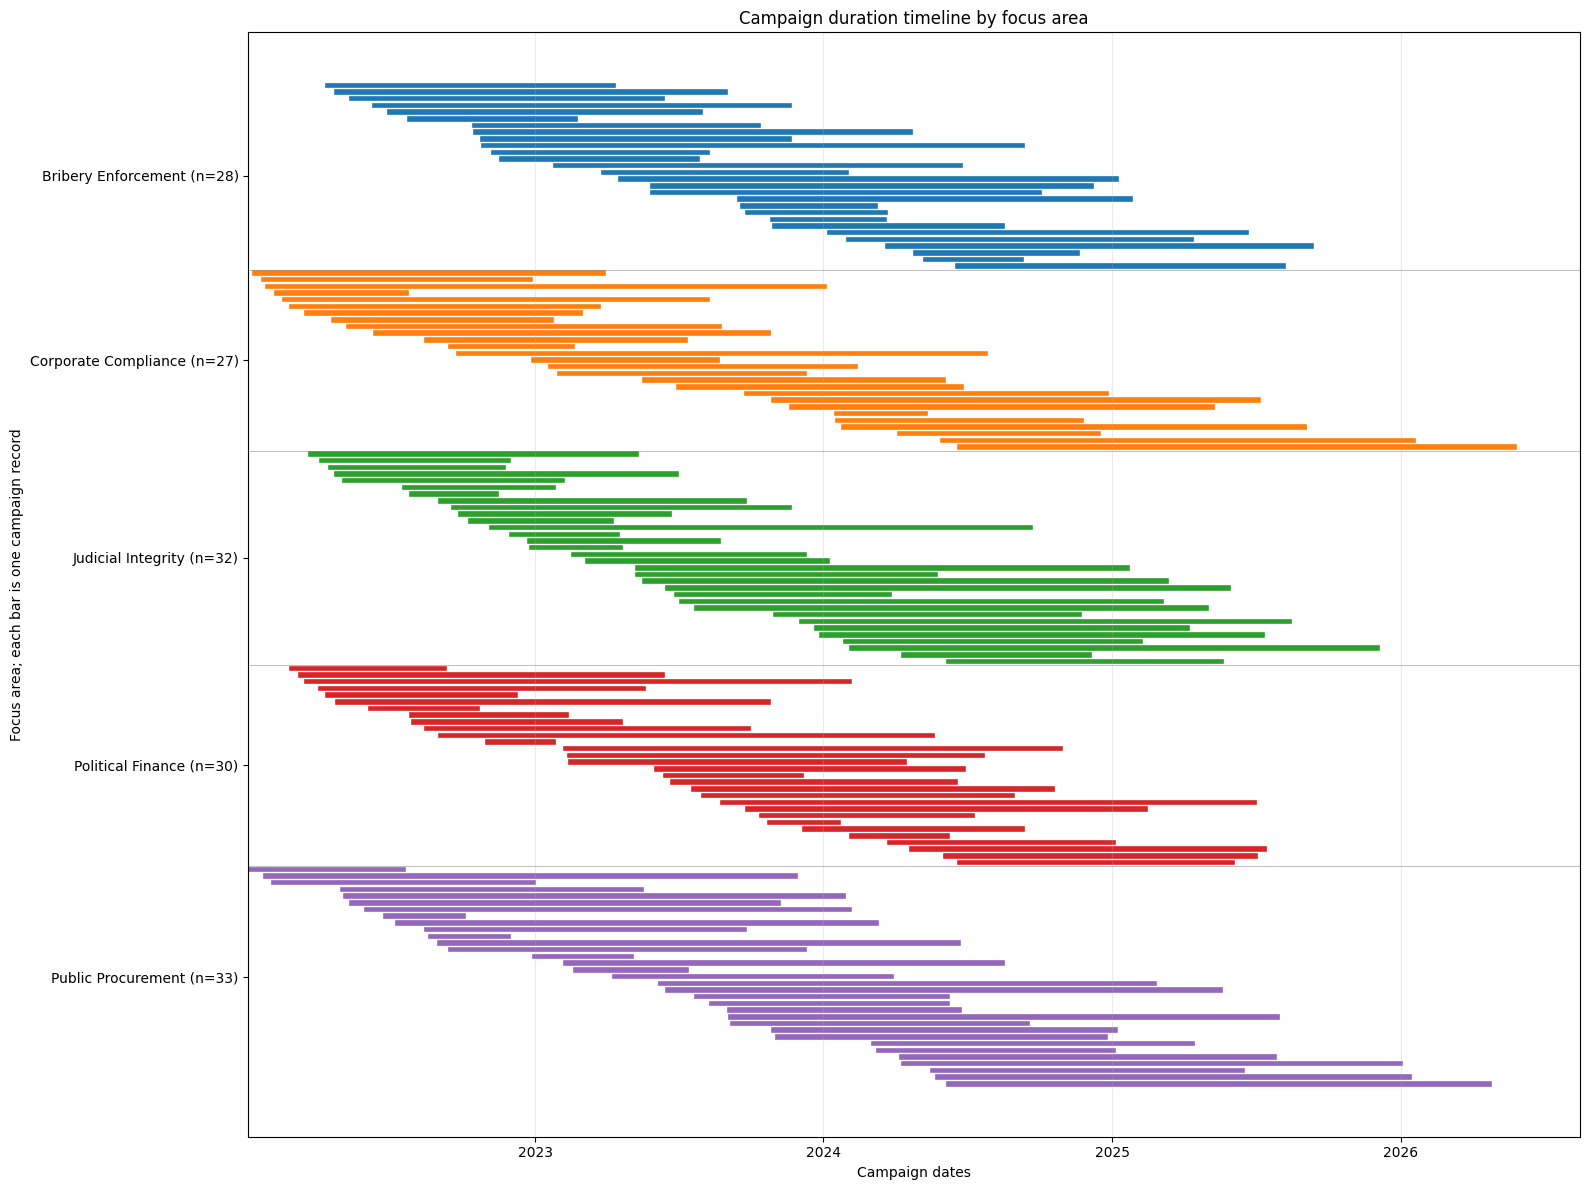

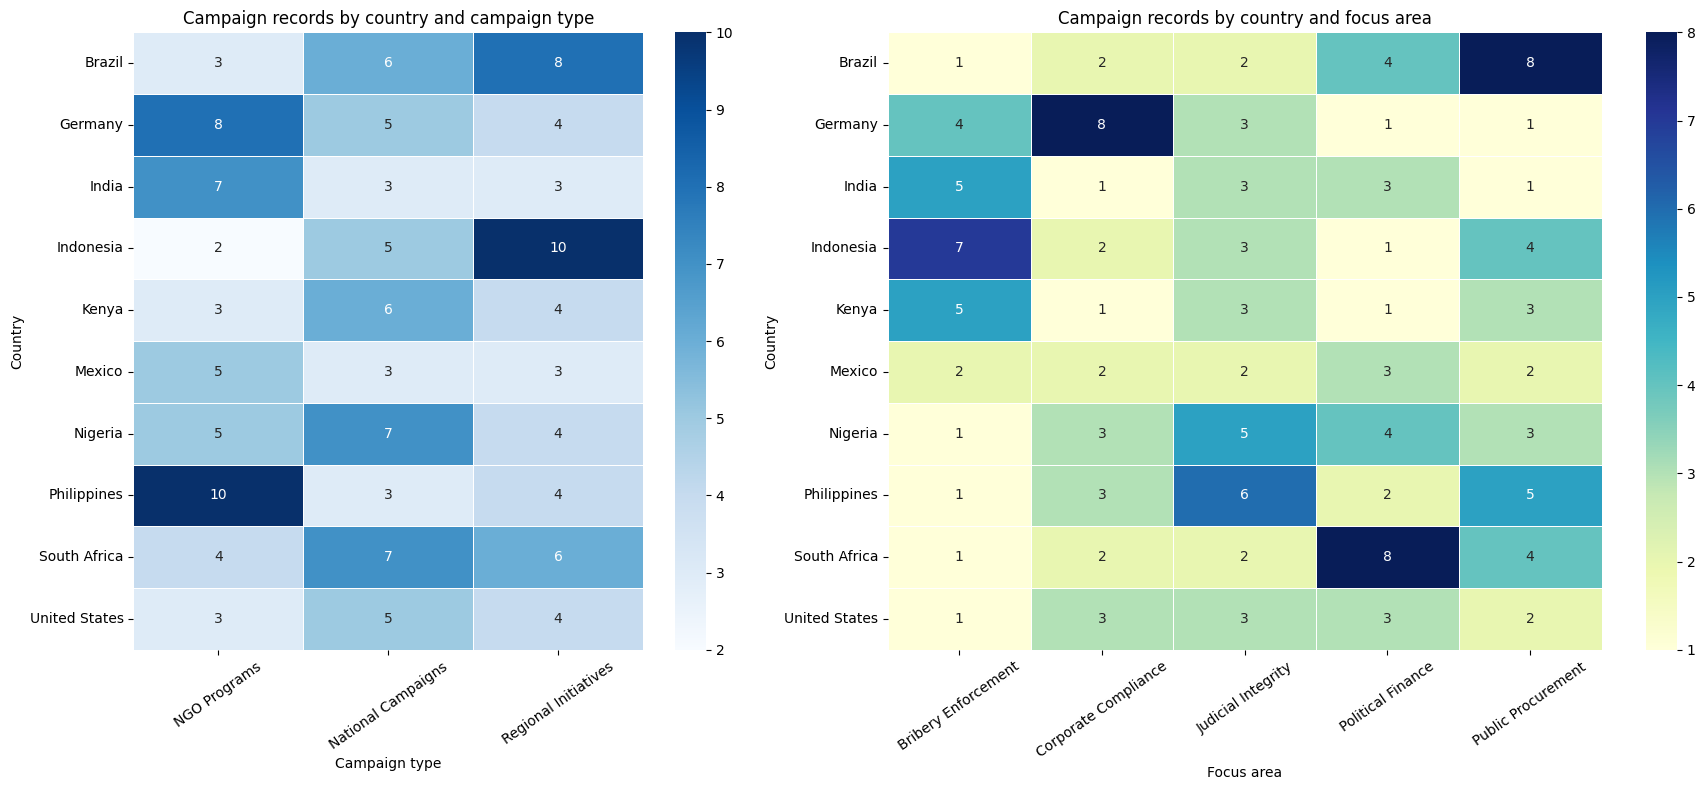

Overall elapsed duration: median 397 days; mean 405.6 days; range 91-716 days.
Campaign interval dates: 2022-01-03 to 2026-05-28.
Country overlap: 3-3 campaign types per country; 10 countries total.
Gantt chart: campaign_duration_gantt.png
Country overlap heatmap: country_overlap_heatmap.png


,campaigns,min_days,q1_days,median_days,mean_days,q3_days,max_days
0,150,91,276.2,397.0,405.6,543.5,716


,campaign_type,campaigns,min_days,median_days,mean_days,max_days
0,NGO Programs,50,93,409.5,409.1,709
1,National Campaigns,50,104,413.5,431.6,712
2,Regional Initiatives,50,91,354.5,376.2,716


,Focus_Area,campaigns,min_days,median_days,mean_days,max_days
4,Public Procurement,33,104,421.0,444.4,707
0,Bribery Enforcement,28,128,400.0,395.0,689
3,Political Finance,30,91,396.5,372.2,693
1,Corporate Compliance,27,118,392.0,418.9,712
2,Judicial Integrity,32,114,381.5,395.1,716


,Continent,Country,campaigns,campaign_types,organizations,focus_areas
0,Africa,Kenya,13,3,5,5
1,Africa,Nigeria,16,3,5,5
2,Africa,South Africa,17,3,5,5
3,Asia,India,13,3,5,5
4,Asia,Indonesia,17,3,5,5
5,Asia,Philippines,17,3,3,5
6,Europe,Germany,17,3,5,5
7,North America,Mexico,11,3,5,5
8,North America,United States,12,3,5,5
9,South America,Brazil,17,3,4,5


,campaign_type_a,campaign_type_b,shared_countries,jaccard_overlap_pct,country_list
0,NGO Programs,National Campaigns,10,100.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
1,NGO Programs,Regional Initiatives,10,100.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
2,National Campaigns,Regional Initiatives,10,100.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."


,organization_a,organization_b,shared_countries,jaccard_overlap_pct,country_list
8,Ethics Forward,Transparency Alliance,10,100.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
2,Accountability Network,Global Integrity Group,9,100.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
1,Accountability Network,Ethics Forward,9,90.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
3,Accountability Network,Transparency Alliance,9,90.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
4,Civic Watch Intl.,Ethics Forward,9,90.0,"Germany, India, Indonesia, Kenya, Mexico, Nige..."
6,Civic Watch Intl.,Transparency Alliance,9,90.0,"Germany, India, Indonesia, Kenya, Mexico, Nige..."
7,Ethics Forward,Global Integrity Group,9,90.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
9,Global Integrity Group,Transparency Alliance,9,90.0,"Brazil, Germany, India, Indonesia, Kenya, Mexi..."
0,Accountability Network,Civic Watch Intl.,8,80.0,"Germany, India, Indonesia, Kenya, Mexico, Nige..."
5,Civic Watch Intl.,Global Integrity Group,8,80.0,"Germany, India, Indonesia, Kenya, Mexico, Nige..."


In [6]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

timeline = clean_df.sort_values(['Focus_Area', 'Start_Date', 'Campaign_ID']).reset_index(drop=True).copy()
timeline['duration_days'] = (timeline['End_Date'] - timeline['Start_Date']).dt.days
assert timeline['duration_days'].ge(0).all()
duration = timeline['duration_days']
duration_overall = pd.DataFrame([{
    'campaigns': len(timeline),
    'min_days': int(duration.min()),
    'q1_days': round(duration.quantile(0.25), 1),
    'median_days': round(duration.median(), 1),
    'mean_days': round(duration.mean(), 1),
    'q3_days': round(duration.quantile(0.75), 1),
    'max_days': int(duration.max()),
}])
duration_by_type = timeline.groupby('campaign_type').agg(
    campaigns=('Campaign_ID', 'nunique'),
    min_days=('duration_days', 'min'),
    median_days=('duration_days', 'median'),
    mean_days=('duration_days', 'mean'),
    max_days=('duration_days', 'max'),
).reset_index().sort_values('campaign_type')
duration_by_focus = timeline.groupby('Focus_Area').agg(
    campaigns=('Campaign_ID', 'nunique'),
    min_days=('duration_days', 'min'),
    median_days=('duration_days', 'median'),
    mean_days=('duration_days', 'mean'),
    max_days=('duration_days', 'max'),
).reset_index().sort_values('median_days', ascending=False)
for duration_table in [duration_by_type, duration_by_focus]:
    duration_table[['median_days', 'mean_days']] = duration_table[['median_days', 'mean_days']].round(1)

country_coverage = clean_df.groupby(['Continent', 'Country']).agg(
    campaigns=('Campaign_ID', 'nunique'),
    campaign_types=('campaign_type', 'nunique'),
    organizations=('Organization', 'nunique'),
    focus_areas=('Focus_Area', 'nunique'),
).reset_index().sort_values(['Continent', 'Country'])
country_by_type = pd.crosstab(clean_df['Country'], clean_df['campaign_type']).sort_index()
country_by_focus = pd.crosstab(clean_df['Country'], clean_df['Focus_Area']).sort_index()
country_by_organization = pd.crosstab(clean_df['Country'], clean_df['Organization']).sort_index()

type_country_sets = {
    campaign_type: set(group['Country'])
    for campaign_type, group in clean_df.groupby('campaign_type')
}
type_overlap_rows = []
for type_a, type_b in combinations(sorted(type_country_sets), 2):
    shared = type_country_sets[type_a] & type_country_sets[type_b]
    union = type_country_sets[type_a] | type_country_sets[type_b]
    type_overlap_rows.append({
        'campaign_type_a': type_a,
        'campaign_type_b': type_b,
        'shared_countries': len(shared),
        'jaccard_overlap_pct': round(100 * len(shared) / len(union), 1),
        'country_list': ', '.join(sorted(shared)),
    })
type_country_overlap = pd.DataFrame(type_overlap_rows)

organization_country_sets = {
    organization: set(group['Country'])
    for organization, group in clean_df.groupby('Organization')
}
organization_overlap_rows = []
for organization_a, organization_b in combinations(sorted(organization_country_sets), 2):
    shared = organization_country_sets[organization_a] & organization_country_sets[organization_b]
    union = organization_country_sets[organization_a] | organization_country_sets[organization_b]
    organization_overlap_rows.append({
        'organization_a': organization_a,
        'organization_b': organization_b,
        'shared_countries': len(shared),
        'jaccard_overlap_pct': round(100 * len(shared) / len(union), 1),
        'country_list': ', '.join(sorted(shared)),
    })
organization_country_overlap = pd.DataFrame(organization_overlap_rows).sort_values(
    ['jaccard_overlap_pct', 'shared_countries'], ascending=False
)

focus_colors = dict(zip(sorted(timeline['Focus_Area'].unique()), sns.color_palette('tab10', timeline['Focus_Area'].nunique())))
fig, ax = plt.subplots(figsize=(16, 12))
for row_number, row in enumerate(timeline.itertuples()):
    ax.barh(
        row_number,
        row.duration_days,
        left=row.Start_Date,
        height=0.82,
        color=focus_colors[row.Focus_Area],
        edgecolor='white',
        linewidth=0.25,
    )
focus_ticks = []
focus_labels = []
for focus_area, group in timeline.groupby('Focus_Area', sort=True):
    focus_ticks.append((group.index.min() + group.index.max()) / 2)
    focus_labels.append(f"{focus_area} (n={len(group)})")
    if group.index.max() < len(timeline) - 1:
        ax.axhline(group.index.max() + 0.5, color='gray', linewidth=0.6, alpha=0.6)
ax.set_yticks(focus_ticks, focus_labels)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Campaign dates')
ax.set_ylabel('Focus area; each bar is one campaign record')
ax.set_title('Campaign duration timeline by focus area')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
gantt_path = workbook_path.with_name('campaign_duration_gantt.png')
fig.savefig(gantt_path, dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1, 1.4]})
sns.heatmap(country_by_type, annot=True, fmt='d', cmap='Blues', linewidths=0.4, ax=axes[0])
axes[0].set_title('Campaign records by country and campaign type')
axes[0].set_xlabel('Campaign type')
axes[0].set_ylabel('Country')
axes[0].tick_params(axis='x', rotation=35)
sns.heatmap(country_by_focus, annot=True, fmt='d', cmap='YlGnBu', linewidths=0.4, ax=axes[1])
axes[1].set_title('Campaign records by country and focus area')
axes[1].set_xlabel('Focus area')
axes[1].set_ylabel('Country')
axes[1].tick_params(axis='x', rotation=35)
fig.tight_layout()
country_heatmap_path = workbook_path.with_name('country_overlap_heatmap.png')
fig.savefig(country_heatmap_path, dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)

with pd.ExcelWriter(profile_output_path, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    duration_overall.to_excel(writer, index=False, sheet_name='Duration_Overall')
    duration_by_type.to_excel(writer, index=False, sheet_name='Duration_By_Type')
    duration_by_focus.to_excel(writer, index=False, sheet_name='Duration_By_Focus')
    timeline[['Campaign_ID', 'campaign_type', 'source_sheet', 'Organization', 'Focus_Area', 'Country', 'City', 'Start_Date', 'End_Date', 'duration_days']].to_excel(writer, index=False, sheet_name='Campaign_Timeline')
    country_coverage.to_excel(writer, index=False, sheet_name='Country_Coverage')
    country_by_type.to_excel(writer, sheet_name='Country_By_Type')
    country_by_focus.to_excel(writer, sheet_name='Country_By_Focus')
    country_by_organization.to_excel(writer, sheet_name='Country_By_Organization')
    type_country_overlap.to_excel(writer, index=False, sheet_name='Type_Country_Overlap')
    organization_country_overlap.to_excel(writer, index=False, sheet_name='Organization_Overlap')

print(f"Overall elapsed duration: median {duration.median():.0f} days; mean {duration.mean():.1f} days; range {duration.min()}-{duration.max()} days.")
print(f"Campaign interval dates: {timeline['Start_Date'].min():%Y-%m-%d} to {timeline['End_Date'].max():%Y-%m-%d}.")
print(f"Country overlap: {country_coverage['campaign_types'].min()}-{country_coverage['campaign_types'].max()} campaign types per country; {len(country_coverage)} countries total.")
print(f"Gantt chart: {gantt_path}")
print(f"Country overlap heatmap: {country_heatmap_path}")
display(duration_overall)
display(duration_by_type)
display(duration_by_focus)
display(country_coverage)
display(type_country_overlap)
display(organization_country_overlap)

## Temporal overlap within countries

Enumerate unordered campaign pairs within each country. Inclusive intervals overlap when each campaign starts on or before the other's end date. A high combined intensity pair has `Intensity_Score_A + Intensity_Score_B >= 15`.

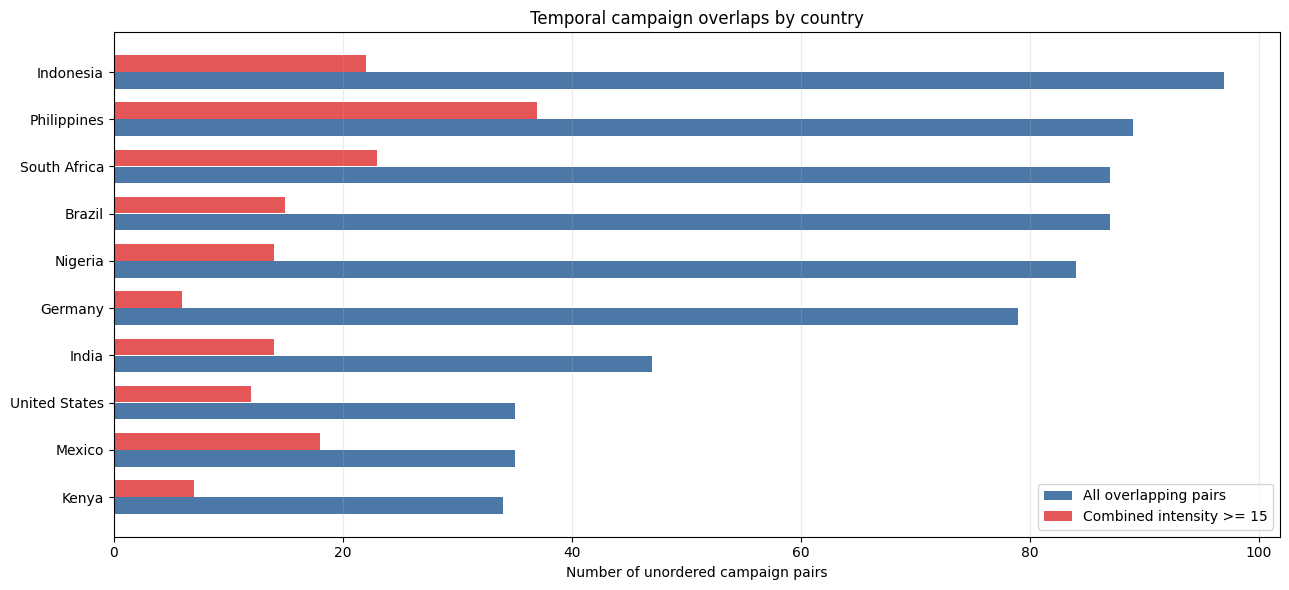

Total overlapping campaign pairs: 674
High combined-intensity pairs (sum >= 15): 168
Country overlap summary: campaign_profile.xlsx
Overlap chart: temporal_overlap_by_country.png


,Country,campaigns,possible_pairs,overlapping_pairs,high_intensity_pairs,mean_combined_intensity,overlap_rate_pct
3,Indonesia,17,136,97,22,11.07,71.3
7,Philippines,17,136,89,37,13.58,65.4
0,Brazil,17,136,87,15,11.18,64.0
8,South Africa,17,136,87,23,11.79,64.0
6,Nigeria,16,120,84,14,11.00,70.0
1,Germany,17,136,79,6,10.20,58.1
2,India,13,78,47,14,12.11,60.3
5,Mexico,11,55,35,18,15.00,63.6
9,United States,12,66,35,12,11.71,53.0
4,Kenya,13,78,34,7,11.62,43.6


,Country,Campaign_ID_A,Campaign_ID_B,campaign_type_A,campaign_type_B,source_sheet_A,source_sheet_B,Organization_A,Organization_B,Start_Date_A,End_Date_A,Start_Date_B,End_Date_B,overlap_start,overlap_end,overlap_days,Intensity_Score_A,Intensity_Score_B,combined_intensity,high_combined_intensity
181,India,NAT-043,NGO-006,National Campaigns,NGO Programs,National Campaigns,NGO Programs,Global Integrity Group,Ethics Forward,2022-01-24,2024-01-06,2022-05-30,2024-02-06,2022-05-30,2024-01-06,587,10,10,20,True
264,Indonesia,NAT-050,REG-035,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Ethics Forward,Accountability Network,2022-08-31,2024-05-21,2022-10-25,2024-09-13,2022-10-25,2024-05-21,575,10,10,20,True
167,India,NAT-023,NAT-043,National Campaigns,National Campaigns,National Campaigns,National Campaigns,Civic Watch Intl.,Global Integrity Group,2022-12-22,2023-08-25,2022-01-24,2024-01-06,2022-12-22,2023-08-25,247,10,10,20,True
169,India,NAT-023,NGO-006,National Campaigns,NGO Programs,National Campaigns,NGO Programs,Civic Watch Intl.,Ethics Forward,2022-12-22,2023-08-25,2022-05-30,2024-02-06,2022-12-22,2023-08-25,247,10,10,20,True
372,Mexico,NGO-032,REG-027,NGO Programs,Regional Initiatives,NGO Programs,Regional Initiatives,Global Integrity Group,Global Integrity Group,2022-03-15,2024-02-06,2023-10-29,2024-11-24,2023-10-29,2024-02-06,101,10,10,20,True
404,Nigeria,NAT-028,REG-022,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Civic Watch Intl.,Accountability Network,2023-05-07,2025-01-23,2023-06-15,2025-05-31,2023-06-15,2025-01-23,589,10,9,19,True
235,Indonesia,NAT-026,NAT-050,National Campaigns,National Campaigns,National Campaigns,National Campaigns,Civic Watch Intl.,Ethics Forward,2022-10-14,2024-04-23,2022-08-31,2024-05-21,2022-10-14,2024-04-23,558,9,10,19,True
243,Indonesia,NAT-026,REG-035,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Civic Watch Intl.,Accountability Network,2022-10-14,2024-04-23,2022-10-25,2024-09-13,2022-10-25,2024-04-23,547,9,10,19,True
370,Mexico,NGO-032,NGO-040,NGO Programs,NGO Programs,NGO Programs,NGO Programs,Global Integrity Group,Transparency Alliance,2022-03-15,2024-02-06,2022-03-07,2023-06-14,2022-03-15,2023-06-14,457,10,9,19,True
376,Mexico,REG-009,REG-027,Regional Initiatives,Regional Initiatives,Regional Initiatives,Regional Initiatives,Global Integrity Group,Global Integrity Group,2023-06-06,2025-02-26,2023-10-29,2024-11-24,2023-10-29,2024-11-24,393,9,10,19,True


In [7]:
from itertools import combinations
import numpy as np

pair_columns = [
    'Country', 'Campaign_ID_A', 'Campaign_ID_B', 'campaign_type_A', 'campaign_type_B',
    'source_sheet_A', 'source_sheet_B', 'Organization_A', 'Organization_B',
    'Start_Date_A', 'End_Date_A', 'Start_Date_B', 'End_Date_B',
    'overlap_start', 'overlap_end', 'overlap_days',
    'Intensity_Score_A', 'Intensity_Score_B', 'combined_intensity',
]
pair_records = []
for country, country_group in clean_df.groupby('Country', sort=True):
    country_rows = country_group.sort_values('Campaign_ID').to_dict('records')
    for first, second in combinations(country_rows, 2):
        if first['Start_Date'] <= second['End_Date'] and second['Start_Date'] <= first['End_Date']:
            overlap_start = max(first['Start_Date'], second['Start_Date'])
            overlap_end = min(first['End_Date'], second['End_Date'])
            combined_intensity = first['Intensity_Score'] + second['Intensity_Score']
            pair_records.append({
                'Country': country,
                'Campaign_ID_A': first['Campaign_ID'],
                'Campaign_ID_B': second['Campaign_ID'],
                'campaign_type_A': first['campaign_type'],
                'campaign_type_B': second['campaign_type'],
                'source_sheet_A': first['source_sheet'],
                'source_sheet_B': second['source_sheet'],
                'Organization_A': first['Organization'],
                'Organization_B': second['Organization'],
                'Start_Date_A': first['Start_Date'],
                'End_Date_A': first['End_Date'],
                'Start_Date_B': second['Start_Date'],
                'End_Date_B': second['End_Date'],
                'overlap_start': overlap_start,
                'overlap_end': overlap_end,
                'overlap_days': (overlap_end - overlap_start).days + 1,
                'Intensity_Score_A': first['Intensity_Score'],
                'Intensity_Score_B': second['Intensity_Score'],
                'combined_intensity': combined_intensity,
            })

overlapping_pairs = pd.DataFrame(pair_records, columns=pair_columns)
assert not overlapping_pairs.duplicated(['Country', 'Campaign_ID_A', 'Campaign_ID_B']).any()
assert (overlapping_pairs['overlap_days'] > 0).all()
overlapping_pairs['high_combined_intensity'] = overlapping_pairs['combined_intensity'] >= 15
high_intensity_overlaps = overlapping_pairs.loc[overlapping_pairs['high_combined_intensity']].sort_values(
    ['combined_intensity', 'overlap_days', 'Country'], ascending=[False, False, True]
)

country_campaign_counts = clean_df.groupby('Country').agg(
    campaigns=('Campaign_ID', 'nunique'),
).reset_index()
country_campaign_counts['possible_pairs'] = country_campaign_counts['campaigns'] * (country_campaign_counts['campaigns'] - 1) // 2
if len(overlapping_pairs):
    observed_pair_counts = overlapping_pairs.groupby('Country').agg(
        overlapping_pairs=('Campaign_ID_A', 'size'),
        high_intensity_pairs=('high_combined_intensity', 'sum'),
        mean_combined_intensity=('combined_intensity', 'mean'),
    ).reset_index()
    country_overlap_summary = country_campaign_counts.merge(observed_pair_counts, on='Country', how='left')
else:
    country_overlap_summary = country_campaign_counts.copy()
    country_overlap_summary['overlapping_pairs'] = 0
    country_overlap_summary['high_intensity_pairs'] = 0
    country_overlap_summary['mean_combined_intensity'] = np.nan
country_overlap_summary[['overlapping_pairs', 'high_intensity_pairs']] = (
    country_overlap_summary[['overlapping_pairs', 'high_intensity_pairs']].fillna(0).astype(int)
)
country_overlap_summary['overlap_rate_pct'] = (
    100 * country_overlap_summary['overlapping_pairs'] / country_overlap_summary['possible_pairs']
).round(1)
country_overlap_summary['mean_combined_intensity'] = country_overlap_summary['mean_combined_intensity'].round(2)
country_overlap_summary = country_overlap_summary.sort_values(
    ['overlapping_pairs', 'Country'], ascending=[False, True]
)

assert overlapping_pairs.groupby('Country').size().sum() == len(overlapping_pairs)
assert high_intensity_overlaps['combined_intensity'].ge(15).all()
assert set(overlapping_pairs['Country']).issubset(set(clean_df['Country']))

fig, ax = plt.subplots(figsize=(13, 6))
plot_summary = country_overlap_summary.sort_values('overlapping_pairs', ascending=True)
positions = np.arange(len(plot_summary))
ax.barh(positions - 0.18, plot_summary['overlapping_pairs'], height=0.35, label='All overlapping pairs', color='#4C78A8')
ax.barh(positions + 0.18, plot_summary['high_intensity_pairs'], height=0.35, label='Combined intensity >= 15', color='#E45756')
ax.set_yticks(positions, plot_summary['Country'])
ax.set_xlabel('Number of unordered campaign pairs')
ax.set_title('Temporal campaign overlaps by country')
ax.legend()
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
overlap_chart_path = workbook_path.with_name('temporal_overlap_by_country.png')
fig.savefig(overlap_chart_path, dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)

with pd.ExcelWriter(profile_output_path, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    country_overlap_summary.to_excel(writer, index=False, sheet_name='Temporal_Overlap_Summary')
    overlapping_pairs.to_excel(writer, index=False, sheet_name='Overlapping_Pairs')
    high_intensity_overlaps.to_excel(writer, index=False, sheet_name='High_Intensity_Pairs')

profile_check = pd.read_excel(profile_output_path, sheet_name='Temporal_Overlap_Summary')
assert int(profile_check['overlapping_pairs'].sum()) == len(overlapping_pairs)
assert len(pd.read_excel(profile_output_path, sheet_name='High_Intensity_Pairs')) == len(high_intensity_overlaps)
print(f"Total overlapping campaign pairs: {len(overlapping_pairs)}")
print(f"High combined-intensity pairs (sum >= 15): {len(high_intensity_overlaps)}")
print(f"Country overlap summary: {profile_output_path}")
print(f"Overlap chart: {overlap_chart_path}")
display(country_overlap_summary)
display(high_intensity_overlaps.head(20))

## Substantive overlap and Venn analysis

Compare all unordered campaign pairs. Same geography means the same country and city; active-date overlap uses inclusive intervals; focus alignment requires an exact `Focus_Area` match (no inferred related categories). Different organizations and campaign types are reported as attributes within Venn regions, not as additional sets. A substantive overlap meets all three core criteria. The Venn areas are illustrative and not proportional to counts.

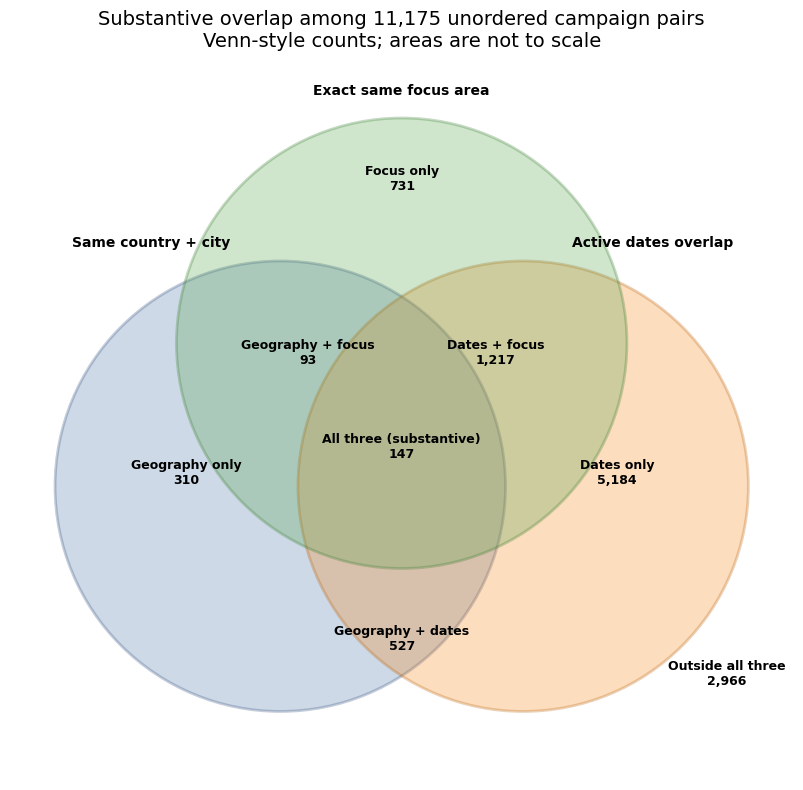

Pair universe: 11,175 unordered distinct campaign pairs.
Substantive overlaps (same country/city + overlapping inclusive dates + exact same focus): 147.
Within the substantive set, 118 pairs have different organizations and 99 have different campaign types.
Venn diagram: substantive_overlap_venn.png


,metric,pair_count,definition
0,All unordered campaign pairs,11175,Pair universe; each pair counted once
1,Same country and city,1077,Venn set: same geography
2,Inclusive active-date overlap,7075,Venn set: date intervals intersect
3,Exact focus-area match,2188,Venn set: identical Focus_Area labels
4,Substantive overlap (all 3),147,Same country/city AND inclusive date overlap A...
5,Substantive pairs with different organizations,118,Attribute within the all-three intersection
6,Substantive pairs with different campaign types,99,Attribute within the all-three intersection
7,Substantive pairs differing by both organizati...,78,Attribute within the all-three intersection
8,Substantive pairs with combined intensity >= 15,31,Combined score = Intensity_Score_A + Intensity...


,venn_region,same_geography,dates_overlap,focus_aligned_exactly,pair_count,different_organization_pairs,different_campaign_type_pairs,both_different_org_and_type,high_intensity_pairs_ge_15
0,Outside all three,False,False,False,2966,2367,1985,1585,756
1,Focus only,False,False,True,731,576,487,378,206
2,Dates only,False,True,False,5184,4160,3511,2836,1416
3,Dates + focus,False,True,True,1217,1017,805,669,352
4,Geography only,True,False,False,310,248,205,164,72
5,Geography + focus,True,False,True,93,76,61,51,26
6,Geography + dates,True,True,False,527,413,347,272,137
7,All three (substantive),True,True,True,147,118,99,78,31


,Campaign_ID_A,Campaign_ID_B,Campaign_Type_A,Campaign_Type_B,Source_Sheet_A,Source_Sheet_B,Organization_A,Organization_B,Country_A,City_A,...,overlap_start,overlap_end,overlap_days,same_geography,dates_overlap,focus_aligned,different_organizations,different_campaign_types,combined_intensity,substantive_overlap
160,NAT-002,NAT-014,National Campaigns,National Campaigns,National Campaigns,National Campaigns,Transparency Alliance,Accountability Network,Kenya,Nairobi,...,2022-07-23,2023-02-25,218,True,True,True,True,False,15,True
212,NAT-002,NGO-016,National Campaigns,NGO Programs,National Campaigns,NGO Programs,Transparency Alliance,Civic Watch Intl.,Kenya,Nairobi,...,2023-09-17,2023-11-23,68,True,True,True,True,True,13,True
548,NAT-004,REG-009,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Global Integrity Group,Global Integrity Group,Mexico,Mexico City,...,2023-10-27,2025-01-08,440,True,True,True,False,True,12,True
628,NAT-005,NAT-044,National Campaigns,National Campaigns,National Campaigns,National Campaigns,Global Integrity Group,Accountability Network,Brazil,Brasilia,...,2023-07-17,2024-06-19,339,True,True,True,True,False,13,True
734,NAT-005,REG-050,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Global Integrity Group,Global Integrity Group,Brazil,Brasilia,...,2023-07-17,2023-10-01,77,True,True,True,False,True,8,True
979,NAT-007,REG-008,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Transparency Alliance,Ethics Forward,South Africa,Pretoria,...,2023-06-29,2023-08-26,59,True,True,True,True,True,13,True
1078,NAT-008,NGO-015,National Campaigns,NGO Programs,National Campaigns,NGO Programs,Civic Watch Intl.,Ethics Forward,Indonesia,Jakarta,...,2022-04-29,2023-01-02,249,True,True,True,True,True,8,True
1160,NAT-008,REG-047,National Campaigns,Regional Initiatives,National Campaigns,Regional Initiatives,Civic Watch Intl.,Civic Watch Intl.,Indonesia,Jakarta,...,2022-06-22,2022-10-05,106,True,True,True,False,True,7,True
1245,NAT-009,NGO-041,National Campaigns,NGO Programs,National Campaigns,NGO Programs,Global Integrity Group,Global Integrity Group,Germany,Berlin,...,2022-11-29,2022-12-02,4,True,True,True,False,True,11,True
1327,NAT-010,NAT-033,National Campaigns,National Campaigns,National Campaigns,National Campaigns,Civic Watch Intl.,Civic Watch Intl.,South Africa,Pretoria,...,2023-10-11,2023-10-27,17,True,True,True,False,False,14,True


In [8]:
from itertools import combinations, product
from matplotlib.patches import Circle

pair_rows = []
records = clean_df.sort_values('Campaign_ID').to_dict('records')
for first, second in combinations(records, 2):
    same_geography = first['Country'] == second['Country'] and first['City'] == second['City']
    dates_overlap = first['Start_Date'] <= second['End_Date'] and second['Start_Date'] <= first['End_Date']
    focus_aligned = first['Focus_Area'] == second['Focus_Area']
    overlap_start = max(first['Start_Date'], second['Start_Date']) if dates_overlap else pd.NaT
    overlap_end = min(first['End_Date'], second['End_Date']) if dates_overlap else pd.NaT
    pair_rows.append({
        'Campaign_ID_A': first['Campaign_ID'],
        'Campaign_ID_B': second['Campaign_ID'],
        'Campaign_Type_A': first['campaign_type'],
        'Campaign_Type_B': second['campaign_type'],
        'Source_Sheet_A': first['source_sheet'],
        'Source_Sheet_B': second['source_sheet'],
        'Organization_A': first['Organization'],
        'Organization_B': second['Organization'],
        'Country_A': first['Country'],
        'City_A': first['City'],
        'Country_B': second['Country'],
        'City_B': second['City'],
        'Focus_Area_A': first['Focus_Area'],
        'Focus_Area_B': second['Focus_Area'],
        'Start_Date_A': first['Start_Date'],
        'End_Date_A': first['End_Date'],
        'Start_Date_B': second['Start_Date'],
        'End_Date_B': second['End_Date'],
        'overlap_start': overlap_start,
        'overlap_end': overlap_end,
        'overlap_days': (overlap_end - overlap_start).days + 1 if dates_overlap else 0,
        'same_geography': same_geography,
        'dates_overlap': dates_overlap,
        'focus_aligned': focus_aligned,
        'different_organizations': first['Organization'] != second['Organization'],
        'different_campaign_types': first['campaign_type'] != second['campaign_type'],
        'combined_intensity': first['Intensity_Score'] + second['Intensity_Score'],
    })

pair_comparisons = pd.DataFrame(pair_rows)
assert len(pair_comparisons) == len(clean_df) * (len(clean_df) - 1) // 2
pair_comparisons['substantive_overlap'] = (
    pair_comparisons['same_geography']
    & pair_comparisons['dates_overlap']
    & pair_comparisons['focus_aligned']
)

region_names = {
    (False, False, False): 'Outside all three',
    (True, False, False): 'Geography only',
    (False, True, False): 'Dates only',
    (False, False, True): 'Focus only',
    (True, True, False): 'Geography + dates',
    (True, False, True): 'Geography + focus',
    (False, True, True): 'Dates + focus',
    (True, True, True): 'All three (substantive)',
}
venn_rows = []
for geography_flag, dates_flag, focus_flag in product([False, True], repeat=3):
    region = pair_comparisons.loc[
        (pair_comparisons['same_geography'] == geography_flag)
        & (pair_comparisons['dates_overlap'] == dates_flag)
        & (pair_comparisons['focus_aligned'] == focus_flag)
    ]
    venn_rows.append({
        'venn_region': region_names[(geography_flag, dates_flag, focus_flag)],
        'same_geography': geography_flag,
        'dates_overlap': dates_flag,
        'focus_aligned_exactly': focus_flag,
        'pair_count': len(region),
        'different_organization_pairs': int(region['different_organizations'].sum()),
        'different_campaign_type_pairs': int(region['different_campaign_types'].sum()),
        'both_different_org_and_type': int((region['different_organizations'] & region['different_campaign_types']).sum()),
        'high_intensity_pairs_ge_15': int((region['combined_intensity'] >= 15).sum()),
    })
venn_intersections = pd.DataFrame(venn_rows)

substantive_pairs = pair_comparisons.loc[pair_comparisons['substantive_overlap']].copy()
substantive_summary = pd.DataFrame([
    ('All unordered campaign pairs', len(pair_comparisons), 'Pair universe; each pair counted once'),
    ('Same country and city', int(pair_comparisons['same_geography'].sum()), 'Venn set: same geography'),
    ('Inclusive active-date overlap', int(pair_comparisons['dates_overlap'].sum()), 'Venn set: date intervals intersect'),
    ('Exact focus-area match', int(pair_comparisons['focus_aligned'].sum()), 'Venn set: identical Focus_Area labels'),
    ('Substantive overlap (all 3)', len(substantive_pairs), 'Same country/city AND inclusive date overlap AND exact focus match'),
    ('Substantive pairs with different organizations', int(substantive_pairs['different_organizations'].sum()), 'Attribute within the all-three intersection'),
    ('Substantive pairs with different campaign types', int(substantive_pairs['different_campaign_types'].sum()), 'Attribute within the all-three intersection'),
    ('Substantive pairs differing by both organization and type', int((substantive_pairs['different_organizations'] & substantive_pairs['different_campaign_types']).sum()), 'Attribute within the all-three intersection'),
    ('Substantive pairs with combined intensity >= 15', int((substantive_pairs['combined_intensity'] >= 15).sum()), 'Combined score = Intensity_Score_A + Intensity_Score_B'),
], columns=['metric', 'pair_count', 'definition'])

criteria = pd.DataFrame([
    ('Pair universe', 'All unordered pairs of distinct Campaign_ID records in the consolidated table.'),
    ('Same geography', 'Country_A == Country_B AND City_A == City_B.'),
    ('Active-date overlap', 'Start_Date_A <= End_Date_B AND Start_Date_B <= End_Date_A; inclusive endpoints.'),
    ('Focus alignment', 'Exact Focus_Area label match only; no related-area inference.'),
    ('Different organization', 'Organization_A != Organization_B; descriptive attribute, not a Venn set.'),
    ('Different campaign type', 'Campaign_Type_A != Campaign_Type_B; descriptive attribute, not a Venn set.'),
    ('Substantive overlap', 'Same geography AND active-date overlap AND exact focus alignment.'),
    ('Venn geometry', 'Region counts are exact; circle areas are illustrative and not proportional.'),
], columns=['metric', 'definition'])

fig, ax = plt.subplots(figsize=(12, 8))
venn_circles = [
    Circle((-0.62, 0.05), 1.15, facecolor='#4C78A8', edgecolor='#2F4B7C', alpha=0.28, linewidth=2),
    Circle((0.62, 0.05), 1.15, facecolor='#F58518', edgecolor='#B85C00', alpha=0.28, linewidth=2),
    Circle((0.0, 0.78), 1.15, facecolor='#54A24B', edgecolor='#347A2A', alpha=0.28, linewidth=2),
]
for circle in venn_circles:
    ax.add_patch(circle)

region_positions = {
    'Geography only': (-1.10, 0.12),
    'Dates only': (1.10, 0.12),
    'Focus only': (0.0, 1.62),
    'Geography + dates': (0.0, -0.73),
    'Geography + focus': (-0.48, 0.73),
    'Dates + focus': (0.48, 0.73),
    'All three (substantive)': (0.0, 0.25),
    'Outside all three': (1.66, -0.91),
}
for _, region_row in venn_intersections.iterrows():
    region_name = region_row['venn_region']
    x, y = region_positions[region_name]
    ax.text(x, y, f"{region_name}\n{int(region_row['pair_count']):,}", ha='center', va='center', fontsize=9, weight='bold')
ax.text(-1.28, 1.27, 'Same country + city', ha='center', fontsize=10, weight='bold')
ax.text(1.28, 1.27, 'Active dates overlap', ha='center', fontsize=10, weight='bold')
ax.text(0.0, 2.05, 'Exact same focus area', ha='center', fontsize=10, weight='bold')
ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-1.45, 2.25)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(f"Substantive overlap among {len(pair_comparisons):,} unordered campaign pairs\nVenn-style counts; areas are not to scale", fontsize=14)
fig.tight_layout()
venn_path = workbook_path.with_name('substantive_overlap_venn.png')
fig.savefig(venn_path, dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)

with pd.ExcelWriter(profile_output_path, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    criteria.to_excel(writer, index=False, sheet_name='Substantive_Method')
    venn_intersections.to_excel(writer, index=False, sheet_name='Venn_Intersections')
    substantive_summary.to_excel(writer, index=False, sheet_name='Substantive_Summary')
    substantive_pairs.to_excel(writer, index=False, sheet_name='Substantive_Pairs')

venn_check = pd.read_excel(profile_output_path, sheet_name='Venn_Intersections')
assert int(venn_check['pair_count'].sum()) == len(pair_comparisons)
assert int(venn_check.loc[venn_check['venn_region'] == 'All three (substantive)', 'pair_count'].iloc[0]) == len(substantive_pairs)
print(f"Pair universe: {len(pair_comparisons):,} unordered distinct campaign pairs.")
print(f"Substantive overlaps (same country/city + overlapping inclusive dates + exact same focus): {len(substantive_pairs)}.")
print(f"Within the substantive set, {int(substantive_pairs['different_organizations'].sum())} pairs have different organizations and {int(substantive_pairs['different_campaign_types'].sum())} have different campaign types.")
print(f"Venn diagram: {venn_path}")
display(substantive_summary)
display(venn_intersections)
display(substantive_pairs.head(20))

## Regional coverage and analytical outputs

Build continent-level outputs for North America, South America, Europe, Africa, Asia, and Oceania. Oceania is retained as an explicit zero-record region. Coverage gaps are assessed against the observed six-continent scope; country-level completeness is not inferred without an expected country list or target coverage.

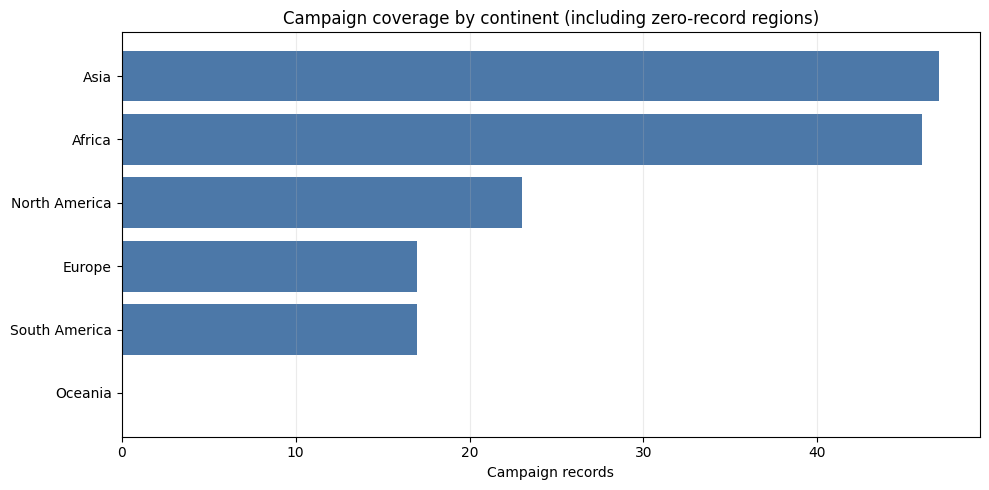

    Continent  campaign_records  share_of_records_pct  countries  campaign_types  focus_areas                        coverage_status
North America                23                  15.3          2               3            5 Observed; completeness not benchmarked
South America                17                  11.3          1               3            5 Observed; completeness not benchmarked
       Europe                17                  11.3          1               3            5 Observed; completeness not benchmarked
       Africa                46                  30.7          3               3            5 Observed; completeness not benchmarked
         Asia                47                  31.3          3               3            5 Observed; completeness not benchmarked
      Oceania                 0                   0.0          0               0            0                             No records
Coverage gap: Oceania has no records; country-level completeness requ

,Continent,campaign_type,campaign_records
0,North America,NGO Programs,8
1,South America,NGO Programs,3
2,Europe,NGO Programs,8
3,Africa,NGO Programs,12
4,Asia,NGO Programs,19
5,Oceania,NGO Programs,0
6,North America,National Campaigns,8
7,South America,National Campaigns,6
8,Europe,National Campaigns,5
9,Africa,National Campaigns,20


,Continent,Focus_Area,campaign_records
0,North America,Bribery Enforcement,3
1,South America,Bribery Enforcement,1
2,Europe,Bribery Enforcement,4
3,Africa,Bribery Enforcement,7
4,Asia,Bribery Enforcement,13
5,Oceania,Bribery Enforcement,0
6,North America,Corporate Compliance,5
7,South America,Corporate Compliance,2
8,Europe,Corporate Compliance,8
9,Africa,Corporate Compliance,6


,validation,passed,details
0,Six requested regions included,True,6 regions in the overview
1,Regional record totals reconcile,True,150 regional rows vs 150 source rows
2,Campaign type totals reconcile,True,150 rows across region/type cells
3,Focus area totals reconcile,True,150 rows across region/focus cells
4,Campaign IDs preserved exactly once,True,150 distinct regional IDs of 150
5,Oceania correctly represented as empty,True,0 Oceania records
6,No unmapped continent values,True,"Observed continent values: ['Africa', 'Asia', ..."


In [9]:
regions = ['North America', 'South America', 'Europe', 'Africa', 'Asia', 'Oceania']
campaign_types = sorted(clean_df['campaign_type'].dropna().unique())
focus_areas = sorted(clean_df['Focus_Area'].dropna().unique())
total_records = len(clean_df)

regional_rows = []
for region in regions:
    region_data = clean_df.loc[clean_df['Continent'] == region]
    region_duration = (region_data['End_Date'] - region_data['Start_Date']).dt.days
    regional_rows.append({
        'Continent': region,
        'campaign_records': len(region_data),
        'share_of_records_pct': round(100 * len(region_data) / total_records, 1) if total_records else 0,
        'countries': region_data['Country'].nunique(),
        'cities': region_data['City'].nunique(),
        'organizations': region_data['Organization'].nunique(),
        'campaign_types': region_data['campaign_type'].nunique(),
        'focus_areas': region_data['Focus_Area'].nunique(),
        'mean_intensity': round(region_data['Intensity_Score'].mean(), 2) if len(region_data) else pd.NA,
        'median_duration_days': round(region_duration.median(), 1) if len(region_data) else pd.NA,
        'first_start_date': region_data['Start_Date'].min() if len(region_data) else pd.NaT,
        'last_end_date': region_data['End_Date'].max() if len(region_data) else pd.NaT,
        'coverage_status': 'No records' if region_data.empty else 'Observed; completeness not benchmarked',
    })
regional_overview = pd.DataFrame(regional_rows)

region_type_matrix = pd.crosstab(clean_df['Continent'], clean_df['campaign_type']).reindex(
    index=regions, columns=campaign_types, fill_value=0
)
region_type_matrix.index.name = 'Continent'
by_region_type = region_type_matrix.reset_index().melt(
    id_vars='Continent', var_name='campaign_type', value_name='campaign_records'
)

region_focus_matrix = pd.crosstab(clean_df['Continent'], clean_df['Focus_Area']).reindex(
    index=regions, columns=focus_areas, fill_value=0
)
region_focus_matrix.index.name = 'Continent'
by_region_focus = region_focus_matrix.reset_index().melt(
    id_vars='Continent', var_name='Focus_Area', value_name='campaign_records'
)

by_country = clean_df.groupby(['Continent', 'Country']).agg(
    campaign_records=('Campaign_ID', 'nunique'),
    cities=('City', 'nunique'),
    organizations=('Organization', 'nunique'),
    campaign_types=('campaign_type', 'nunique'),
    focus_areas=('Focus_Area', 'nunique'),
).reset_index().sort_values(['Continent', 'Country'])

coverage_gaps = pd.DataFrame([
    {
        'geographic_scope': region,
        'observed_records': int(regional_overview.loc[regional_overview['Continent'] == region, 'campaign_records'].iloc[0]),
        'assessment': 'No records in this region' if regional_overview.loc[regional_overview['Continent'] == region, 'campaign_records'].iloc[0] == 0 else 'Region represented; completeness against a target not assessed',
    }
    for region in regions
])
coverage_gaps.loc[len(coverage_gaps)] = {
    'geographic_scope': 'Country-level completeness',
    'observed_records': pd.NA,
    'assessment': 'Cannot identify missing countries without an expected country list or target coverage.'
}

regional_sheets = {region: clean_df.loc[clean_df['Continent'] == region].copy() for region in regions}
combined_regional_ids = pd.concat(
    [frame['Campaign_ID'] for frame in regional_sheets.values()], ignore_index=True
)
validation_rows = [
    ('Six requested regions included', set(regional_overview['Continent']) == set(regions), f'{len(regional_overview)} regions in the overview'),
    ('Regional record totals reconcile', int(regional_overview['campaign_records'].sum()) == total_records, f"{int(regional_overview['campaign_records'].sum())} regional rows vs {total_records} source rows"),
    ('Campaign type totals reconcile', int(by_region_type['campaign_records'].sum()) == total_records, f"{int(by_region_type['campaign_records'].sum())} rows across region/type cells"),
    ('Focus area totals reconcile', int(by_region_focus['campaign_records'].sum()) == total_records, f"{int(by_region_focus['campaign_records'].sum())} rows across region/focus cells"),
    ('Campaign IDs preserved exactly once', combined_regional_ids.nunique() == total_records and sorted(combined_regional_ids.tolist()) == sorted(clean_df['Campaign_ID'].tolist()), f'{combined_regional_ids.nunique()} distinct regional IDs of {total_records}'),
    ('Oceania correctly represented as empty', len(regional_sheets['Oceania']) == 0, f"{len(regional_sheets['Oceania'])} Oceania records"),
    ('No unmapped continent values', clean_df['Continent'].isin(regions).all(), f"Observed continent values: {sorted(clean_df['Continent'].dropna().unique().tolist())}"),
]
validation = pd.DataFrame(validation_rows, columns=['validation', 'passed', 'details'])
assert validation['passed'].all(), validation.loc[~validation['passed']].to_dict('records')

fig, ax = plt.subplots(figsize=(10, 5))
plot_regions = regional_overview.sort_values('campaign_records', ascending=True)
ax.barh(plot_regions['Continent'], plot_regions['campaign_records'], color='#4C78A8')
ax.set_xlabel('Campaign records')
ax.set_title('Campaign coverage by continent (including zero-record regions)')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
regional_chart_path = workbook_path.with_name('regional_coverage.png')
fig.savefig(regional_chart_path, dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)

regional_output_path = workbook_path.with_name('regional_analytical_outputs.xlsx')
with pd.ExcelWriter(regional_output_path, engine='openpyxl', date_format='yyyy-mm-dd', datetime_format='yyyy-mm-dd') as writer:
    regional_overview.to_excel(writer, index=False, sheet_name='Regional_Overview')
    by_region_type.to_excel(writer, index=False, sheet_name='By_Region_Type')
    by_region_focus.to_excel(writer, index=False, sheet_name='By_Region_Focus')
    by_country.to_excel(writer, index=False, sheet_name='By_Country')
    coverage_gaps.to_excel(writer, index=False, sheet_name='Coverage_Gaps')
    validation.to_excel(writer, index=False, sheet_name='Validation')
    for region, frame in regional_sheets.items():
        frame.to_excel(writer, index=False, sheet_name=region.replace(' ', '_'))

regional_readback = pd.read_excel(regional_output_path, sheet_name='Regional_Overview')
assert int(regional_readback['campaign_records'].sum()) == total_records
assert int(pd.read_excel(regional_output_path, sheet_name='Oceania').shape[0]) == 0
assert pd.read_excel(regional_output_path, sheet_name='Validation')['passed'].all()
print(regional_overview[['Continent', 'campaign_records', 'share_of_records_pct', 'countries', 'campaign_types', 'focus_areas', 'coverage_status']].to_string(index=False))
print(f'Coverage gap: Oceania has no records; country-level completeness requires an external target list.')
print(f'All regional validation checks passed: {validation["passed"].sum()} of {len(validation)}.')
print(f'Regional workbook: {regional_output_path}')
print(f'Regional coverage chart: {regional_chart_path}')
display(by_region_type)
display(by_region_focus)
display(validation)